# State analysis: omega, ophi, ophps, oppc

Cis/trans macrostate free-energy analysis for the four biased backbone dihedrals. Each figure below is organized **by category** (one analysis type per figure) and **integrates both data sources as subplots**: the top row is the single long metadynamics trajectory for each dihedral (`single_trajectory_state_analysis/`), and the bottom row is the corresponding 8-replica ensemble (`omega_state_analysis/`, `oppc_state_analysis/`) — ophi and ophps have no ensemble runs, so those bottom-row panels are left blank.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SINGLE_DIR = Path("single_trajectory_state_analysis")
ANGLES = ["omega", "ophi", "ophps", "oppc"]
REPLICA_ANGLES = ["omega", "oppc"]

STATE_ORDER = ["CCC", "CCT", "CTC", "CTT", "TCC", "TCT", "TTC", "TTT"]
STATE_COLORS = dict(zip(STATE_ORDER, plt.rcParams["axes.prop_cycle"].by_key()["color"]))


def load_single(angle, name):
    return pd.read_csv(SINGLE_DIR / angle / f"{angle}_{name}.csv")


def load_replica(angle, name):
    return pd.read_csv(Path(f"{angle}_state_analysis") / "state_analysis_results" / name)


def make_grid(figsize=(15, 7)):
    """2x4 grid: row 0 = single trajectory (all 4 angles), row 1 = 8-replica ensemble (omega, oppc only)."""
    fig, axes = plt.subplots(2, 4, figsize=figsize)
    for col, angle in enumerate(ANGLES):
        axes[0, col].set_title(angle)
        if angle in REPLICA_ANGLES:
            axes[1, col].set_title(angle)
        else:
            axes[1, col].axis("off")
            axes[1, col].text(
                0.5, 0.5, "no ensemble\ndata", ha="center", va="center",
                transform=axes[1, col].transAxes, color="gray", fontsize=9,
            )
    axes[0, 0].set_ylabel("Single trajectory")
    axes[1, 0].set_ylabel("8-replica ensemble")
    return fig, axes

## Late-block macrostate free energies

Approximate $\Delta F$ per cis/trans macrostate from the late (equilibrated) blocks of each run.

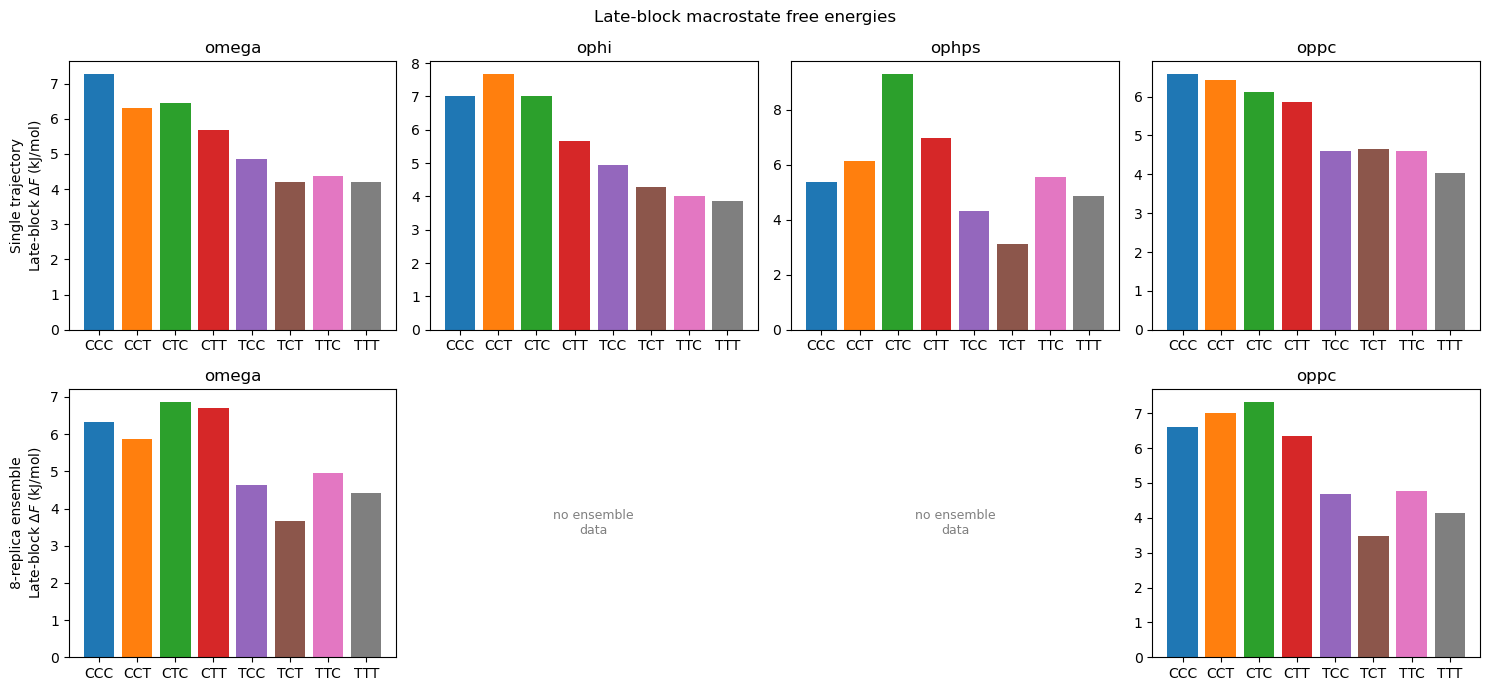

In [2]:
fig, axes = make_grid()

for col, angle in enumerate(ANGLES):
    df = load_single(angle, "late_state_summary").set_index("state").reindex(STATE_ORDER)
    axes[0, col].bar(df.index, df["free_energy"], color=[STATE_COLORS[s] for s in df.index])

for col, angle in enumerate(ANGLES):
    if angle in REPLICA_ANGLES:
        df = load_replica(angle, "all_replicas_late_population_average.csv").set_index("state").reindex(STATE_ORDER)
        axes[1, col].bar(df.index, df["free_energy"], color=[STATE_COLORS[s] for s in df.index])

axes[0, 0].set_ylabel("Single trajectory\n" + r"Late-block $\Delta F$ (kJ/mol)")
axes[1, 0].set_ylabel("8-replica ensemble\n" + r"Late-block $\Delta F$ (kJ/mol)")
fig.suptitle("Late-block macrostate free energies")
fig.tight_layout()
fig.savefig(SINGLE_DIR / "integrated_late_free_energies.png", dpi=150)
plt.show()

## Late-block macrostate populations

Error bars are the standard deviation across blocks (single trajectory, top row) or the SEM across the 8 replicas (ensemble, bottom row).

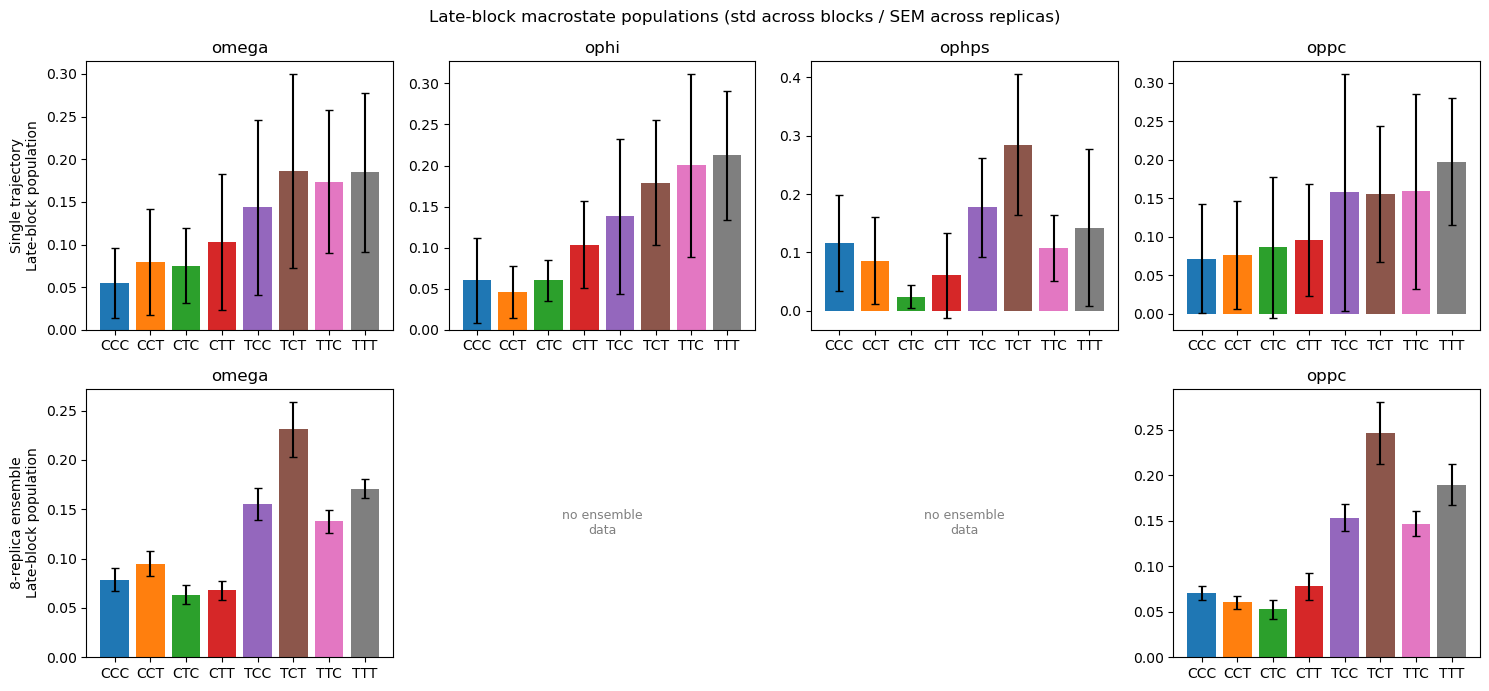

In [3]:
fig, axes = make_grid()

for col, angle in enumerate(ANGLES):
    df = load_single(angle, "late_state_summary").set_index("state").reindex(STATE_ORDER)
    axes[0, col].bar(
        df.index, df["population"], yerr=df["population_std_across_blocks"],
        color=[STATE_COLORS[s] for s in df.index], capsize=3,
    )

for col, angle in enumerate(ANGLES):
    if angle in REPLICA_ANGLES:
        df = load_replica(angle, "all_replicas_late_population_average.csv").set_index("state").reindex(STATE_ORDER)
        axes[1, col].bar(
            df.index, df["population"], yerr=df["population_sem_across_replicas"],
            color=[STATE_COLORS[s] for s in df.index], capsize=3,
        )

axes[0, 0].set_ylabel("Single trajectory\nLate-block population")
axes[1, 0].set_ylabel("8-replica ensemble\nLate-block population")
fig.suptitle("Late-block macrostate populations (std across blocks / SEM across replicas)")
fig.tight_layout()
fig.savefig(SINGLE_DIR / "integrated_late_populations.png", dpi=150)
plt.show()

## Minimum free-energy state over time

Which macrostate has the lowest cumulative free energy as more of the trajectory (or ensemble) is folded in.

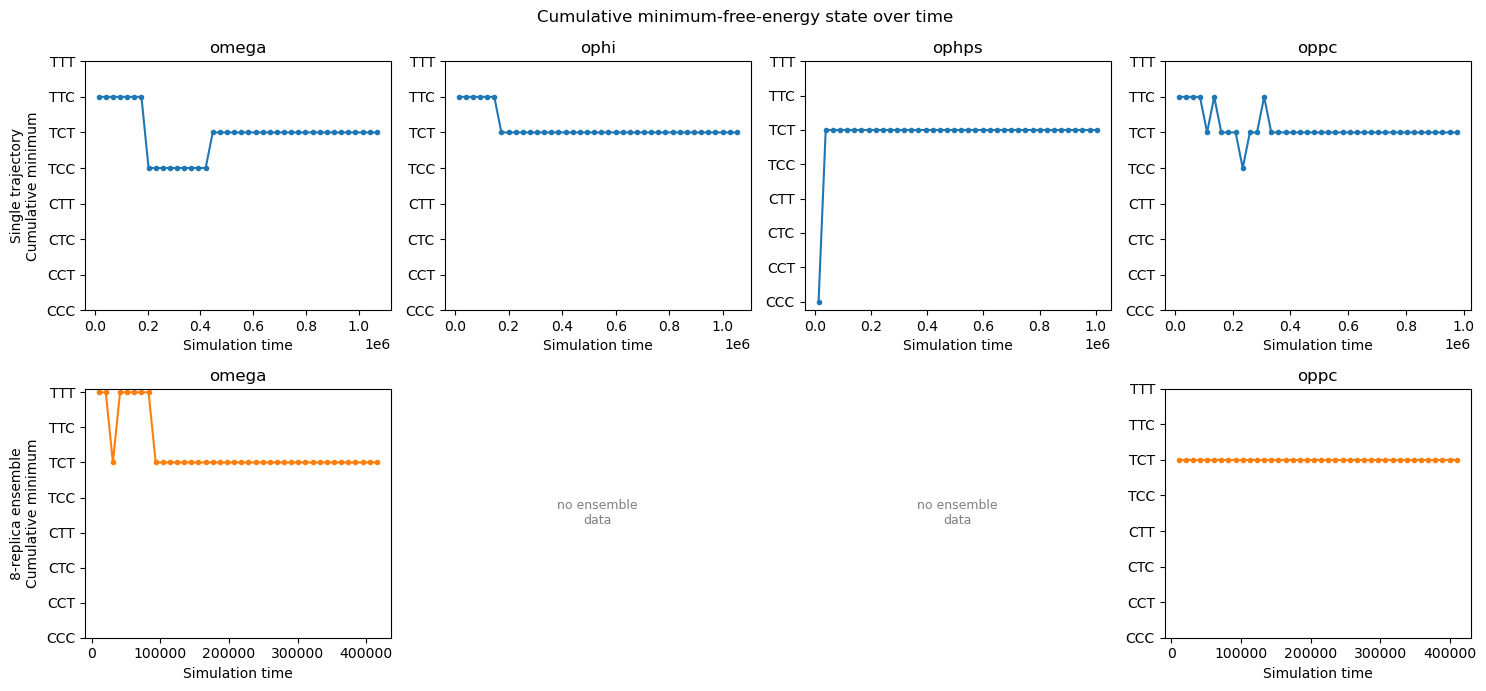

In [4]:
fig, axes = make_grid()

for col, angle in enumerate(ANGLES):
    df = load_single(angle, "cumulative_minimum_over_time")
    y = df["minimum_state"].apply(STATE_ORDER.index)
    axes[0, col].plot(df["midpoint_time"], y, marker="o", ms=3)
    axes[0, col].set_yticks(range(len(STATE_ORDER)))
    axes[0, col].set_yticklabels(STATE_ORDER)

for col, angle in enumerate(ANGLES):
    if angle in REPLICA_ANGLES:
        df = load_replica(angle, "minimum_state_over_time_start0.csv")
        y = df["minimum_state"].apply(STATE_ORDER.index)
        axes[1, col].plot(df["end_time"], y, marker="o", ms=3, color="tab:orange")
        axes[1, col].set_yticks(range(len(STATE_ORDER)))
        axes[1, col].set_yticklabels(STATE_ORDER)
    axes[1, col].set_xlabel("Simulation time")
    axes[0, col].set_xlabel("Simulation time")

axes[0, 0].set_ylabel("Single trajectory\nCumulative minimum")
axes[1, 0].set_ylabel("8-replica ensemble\nCumulative minimum")
fig.suptitle("Cumulative minimum-free-energy state over time")
fig.tight_layout()
fig.savefig(SINGLE_DIR / "integrated_minimum_state_over_time.png", dpi=150)
plt.show()

## Population convergence over time

Cumulative, block-averaged macrostate populations vs. simulation time. The ensemble row additionally shades the SEM across the 8 replicas.

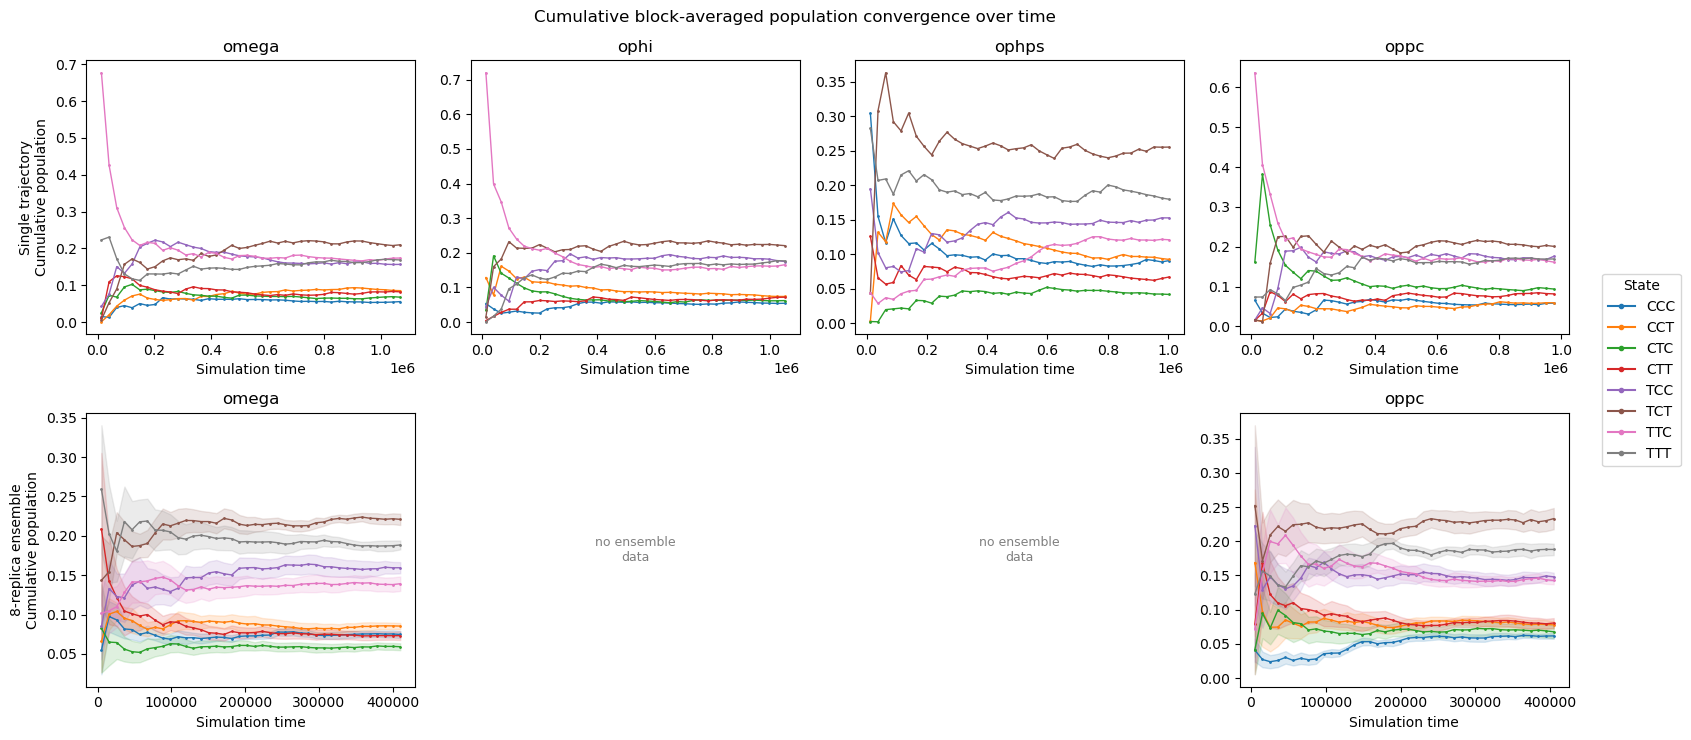

In [5]:
fig, axes = make_grid(figsize=(16, 7.5))

for col, angle in enumerate(ANGLES):
    df = load_single(angle, "cumulative_state_free_energies")
    for state in STATE_ORDER:
        sub = df[df["state"] == state]
        if len(sub):
            axes[0, col].plot(sub["midpoint_time"], sub["population"], color=STATE_COLORS[state], marker=".", ms=2, lw=1)
    axes[0, col].set_xlabel("Simulation time")

for col, angle in enumerate(ANGLES):
    if angle in REPLICA_ANGLES:
        df = load_replica(angle, "ensemble_cumulative_populations_start0.csv")
        for state in STATE_ORDER:
            sub = df[df["state"] == state]
            if len(sub):
                axes[1, col].plot(sub["midpoint_time"], sub["population"], color=STATE_COLORS[state], marker=".", ms=2, lw=1)
                axes[1, col].fill_between(
                    sub["midpoint_time"], sub["population"] - sub["population_sem"],
                    sub["population"] + sub["population_sem"], color=STATE_COLORS[state], alpha=0.15,
                )
        axes[1, col].set_xlabel("Simulation time")

axes[0, 0].set_ylabel("Single trajectory\nCumulative population")
axes[1, 0].set_ylabel("8-replica ensemble\nCumulative population")
handles = [plt.Line2D([0], [0], color=STATE_COLORS[s], marker=".", label=s) for s in STATE_ORDER]
fig.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), title="State")
fig.suptitle("Cumulative block-averaged population convergence over time")
fig.tight_layout()
fig.savefig(SINGLE_DIR / "integrated_population_convergence.png", dpi=150, bbox_inches="tight")
plt.show()

## Late-block population per replica (ensemble only)

How much the 8 individual replicas agree with each other; there is no single-trajectory equivalent of this panel, since a single trajectory has no replicate spread.

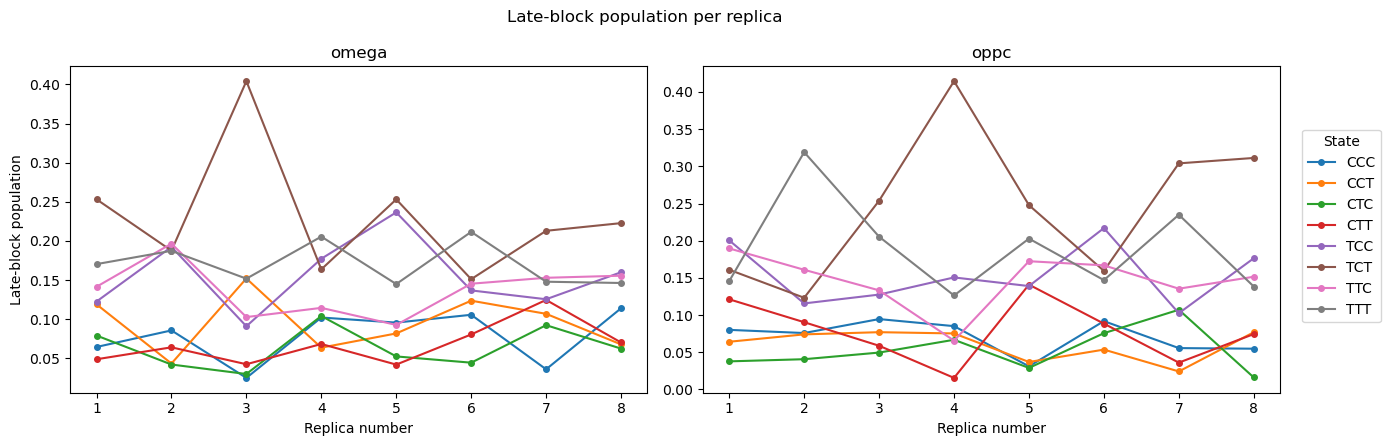

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, angle in zip(axes, REPLICA_ANGLES):
    df = load_replica(angle, "all_replicas_late_results.csv")
    for state in STATE_ORDER:
        sub = df[df["state"] == state].sort_values("replica_number")
        if len(sub):
            ax.plot(sub["replica_number"], sub["population"], color=STATE_COLORS[state], label=state, marker="o", ms=4)
    ax.set_title(angle)
    ax.set_xlabel("Replica number")
axes[0].set_ylabel("Late-block population")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), title="State")
fig.suptitle("Late-block population per replica")
fig.tight_layout()
fig.savefig(SINGLE_DIR / "integrated_late_populations_by_replica.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary tables

In [7]:
single_summary = pd.read_csv(SINGLE_DIR / "single_trajectory_minimum_summary.csv")
single_summary

,system,n_analyzed_frames,start_time,end_time,global_minimum_state,global_minimum_population,late_minimum_state,late_minimum_population,final_cumulative_minimum_state,final_cumulative_minimum_population,global_weight_ess,global_weight_ess_fraction
0,omega,2706476,0.0,1082590.0,TTC,0.212872,TCT,0.185930,TCT,0.209900,138841.652905,0.051300
1,ophi,2662097,0.0,1064838.4,TTT,0.228431,TTT,0.212307,TCT,0.220726,157844.149009,0.059293
2,ophps,2541041,0.0,1016416.0,TCT,0.294927,TCT,0.284818,TCT,0.255288,167255.091298,0.065821
3,oppc,2471178,0.0,988470.8,TCC,0.256518,TTT,0.197529,TCT,0.200829,203318.208808,0.082276


In [8]:
for angle in REPLICA_ANGLES:
    print(f"--- {angle} (8-replica ensemble) ---")
    display(load_replica(angle, "all_replicas_minimum_summary.csv"))

--- omega (8-replica ensemble) ---


,replica,replica_number,n_frames,start_time,end_time,global_minimum_state,global_minimum_population,late_minimum_state,late_minimum_population,global_weight_ess,global_weight_ess_fraction
0,replica_1,1,207739,0.0,415476.0,TTT,0.259711,TCT,0.253233,10873.502463,0.052342
1,replica_2,2,207739,0.0,415476.0,TTT,0.228010,TTC,0.196615,10220.247201,0.049198
2,replica_3,3,207739,0.0,415476.0,TCT,0.439974,TCT,0.404062,9324.457476,0.044885
3,replica_4,4,207739,0.0,415476.0,TTT,0.234018,TTT,0.205590,10698.022823,0.051497
4,replica_5,5,207739,0.0,415476.0,TCC,0.278167,TCT,0.253150,10632.399614,0.051182
5,replica_6,6,207739,0.0,415476.0,TTC,0.222252,TTT,0.211638,10307.263699,0.049616
6,replica_7,7,207739,0.0,415476.0,TCT,0.212090,TCT,0.213006,10861.732942,0.052285
7,replica_8,8,207739,0.0,415476.0,TTT,0.208272,TCT,0.222798,10993.751198,0.052921


--- oppc (8-replica ensemble) ---


,replica,replica_number,n_frames,start_time,end_time,global_minimum_state,global_minimum_population,late_minimum_state,late_minimum_population,global_weight_ess,global_weight_ess_fraction
0,replica_1,1,205021,0.0,410040.0,TCT,0.312258,TCC,0.200473,16989.221374,0.082866
1,replica_2,2,205021,0.0,410040.0,TCC,0.299158,TTT,0.319083,16958.459352,0.082716
2,replica_3,3,205021,0.0,410040.0,TCT,0.239153,TCT,0.253789,17961.728914,0.087609
3,replica_4,4,205021,0.0,410040.0,TCT,0.616299,TCT,0.414525,16122.855684,0.078640
4,replica_5,5,205021,0.0,410040.0,TTT,0.306656,TCT,0.247791,16773.022761,0.081811
5,replica_6,6,205021,0.0,410040.0,TTT,0.241897,TCC,0.216968,17189.918032,0.083845
6,replica_7,7,205021,0.0,410040.0,TCT,0.328462,TCT,0.304009,16792.605730,0.081907
7,replica_8,8,205021,0.0,410040.0,TCT,0.249159,TCT,0.311286,17194.247304,0.083866
